In [59]:
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.datasets import load_breast_cancer
from sklearn.tree import plot_tree, DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [60]:
df = load_breast_cancer(as_frame=True)
X = df.data
y = df.target

In [61]:
print(X.shape)
print(list(df.target_names))
display(X.head())

(569, 30)
[np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [62]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, stratify=y)

In [63]:
mod = DecisionTreeClassifier(max_depth=1, random_state=42)
mod.fit(X_train, y_train)
y_pred = mod.predict(X_test)

print("Accuracy", accuracy_score(y_test, y_pred))

Accuracy 0.8947368421052632


[Text(0.5, 0.75, 'worst perimeter <= 105.95\ngini = 0.468\nsamples = 455\nvalue = [170, 285]'),
 Text(0.25, 0.25, 'gini = 0.095\nsamples = 279\nvalue = [14, 265]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.201\nsamples = 176\nvalue = [156, 20]'),
 Text(0.625, 0.5, '  False')]

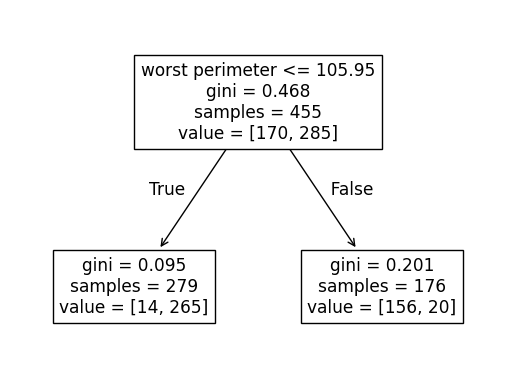

In [64]:
plot_tree(mod, feature_names=X.columns)

In [65]:
ada_mod = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1,random_state=42),
    n_estimators=50,
    learning_rate=1,
    random_state=42
)

ada_mod.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,n_estimators,50
,learning_rate,1
,algorithm,'deprecated'
,random_state,42
,criterion,'gini'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [66]:
y_pred_ada = ada_mod.predict(X_test)
print('AdaBoost accuracy:',(round(accuracy_score(y_test, y_pred_ada),3)))

AdaBoost accuracy: 0.974


In [67]:
import matplotlib.pyplot as plt

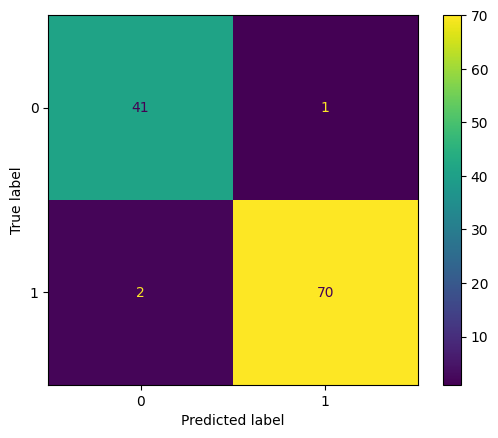

In [68]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_ada)

In [69]:
print(classification_report(y_test, y_pred_ada))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [70]:
details = pd.DataFrame({
    'Round': range(1, len(ada_mod.estimators_)+1),
    'Weighted Error': ada_mod.estimator_errors_[:len(ada_mod.estimators_)],
    'Voting Weight': ada_mod.estimator_weights_[:len(ada_mod.estimators_)]
})

display(details.head(10))

,Round,Weighted Error,Voting Weight
0,1,0.074725,2.516272
1,2,0.177029,1.536604
2,3,0.187571,1.465870
3,4,0.233281,1.189875
4,5,0.271337,0.987847
5,6,0.271300,0.988037
6,7,0.246106,1.119488
7,8,0.290143,0.894690
8,9,0.252863,1.083402
9,10,0.342886,0.650458


In [71]:
cv_scores = cross_val_score(ada_mod, X_train, y_train, cv=5, scoring="accuracy")
print('CV Accuracy for each fold:', cv_scores.round(4))
print("Mean CV accuracy:", round(cv_scores.mean(), 4))

CV Accuracy for each fold: [0.956  1.     0.8791 0.978  0.9121]
Mean CV accuracy: 0.9451


In [73]:
param_grid = {
    "n_estimators": [30,50,100],
    "learning_rate": [0.1, 0.5, 1.0]
}

grid = GridSearchCV(
    estimator=AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        random_state=42
    ),
    param_grid=param_grid,
    cv = 5,
    scoring="accuracy"
)

In [74]:
grid.fit(X_train, y_train)

,estimator,AdaBoostClass...ndom_state=42)
,param_grid,"{'learning_rate': [0.1, 0.5, ...], 'n_estimators': [30, 50, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [75]:
print("Best Parametere: ", grid.best_params_)
print("Best Mean CV Accuracy: ", round(grid.best_score_,4))
print("Tuned Model Test Accuracy: ", round(grid.score(X_test, y_test), 4))

Best Parametere:  {'learning_rate': 1.0, 'n_estimators': 100}
Best Mean CV Accuracy:  0.956
Tuned Model Test Accuracy:  0.9825


In [76]:
best_mod = grid.best_estimator_

In [80]:
y_pred_best = best_mod.predict(X_test)
print("Best Accuracy: ", round(accuracy_score(y_test, y_pred_best), 3))

Best Accuracy:  0.982
